# Lab – EDA Bivariate Analysis: Diving into Amazon UK Product Insights (Part II)

**Objective:** understand how product categories relate to best-seller status, prices and ratings on Amazon UK, in order to inform pricing and assortment decisions.

**Dataset:** Amazon UK products (Kaggle) – 2,443,651 products across 296 categories. Columns used: `stars, reviews, price, isBestSeller, boughtInLastMonth, category`.

## 0. Setup & data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Adjust the path to where the CSV is stored on your machine
DATA_PATH = "amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH)
# The lab refers to the column as `category`; the raw file calls it `categoryName`
df = df.rename(columns={"categoryName": "category"})
print(df.shape)
df.head()

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.700,15308,21.990,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.700,98099,23.990,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.700,15308,21.990,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.700,7205,31.990,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.600,1881,17.990,False,0,Hi-Fi Speakers


In [2]:
df.info()
df[["stars", "reviews", "price", "boughtInLastMonth"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


,stars,reviews,price,boughtInLastMonth
count,"2,443,651.000","2,443,651.000","2,443,651.000","2,443,651.000"
mean,2.153,480.628,89.244,25.897
std,2.195,"5,944.124",345.609,240.484
min,0.000,0.000,0.000,0.000
25%,0.000,0.000,9.990,0.000
50%,0.000,0.000,19.090,0.000
75%,4.400,59.000,45.990,0.000
max,5.000,"1,356,658.000","100,000.000","50,000.000"


# Part 1 – Best-seller trends across product categories

### 1.1 Crosstab: `category` × `isBestSeller`

In [3]:
ct = pd.crosstab(df["category"], df["isBestSeller"])
ct.columns = ["Not best-seller", "Best-seller"]
ct["Total"] = ct.sum(axis=1)
ct["Best-seller share"] = ct["Best-seller"] / ct["Total"]

ct_sorted = ct.sort_values("Best-seller share", ascending=False)
print("Top 15 categories by best-seller share (all categories):")
ct_sorted.head(15)

Top 15 categories by best-seller share (all categories):


,Not best-seller,Best-seller,Total,Best-seller share
category,,,,
Grocery,9008,556,9564,0.058
Smart Home Security & Lighting,98,6,104,0.058
Health & Personal Care,9017,552,9569,0.058
Mobile Phone Accessories,248,11,259,0.042
Power & Hand Tools,8353,306,8659,0.035
"Billiard, Snooker & Pool",241,8,249,0.032
Pet Supplies,9152,285,9437,0.030
Home Brewing & Wine Making,239,7,246,0.028
Wind Instruments,243,7,250,0.028


In [4]:
# Very small categories can show extreme shares (e.g. 1 product = 100%).
# Same ranking restricted to categories with at least 100 products:
MIN_PRODUCTS = 100
ct_sorted_min = ct_sorted[ct_sorted["Total"] >= MIN_PRODUCTS]
print(f"Top 15 categories by best-seller share (>= {MIN_PRODUCTS} products):")
ct_sorted_min.head(15)

Top 15 categories by best-seller share (>= 100 products):


,Not best-seller,Best-seller,Total,Best-seller share
category,,,,
Grocery,9008,556,9564,0.058
Smart Home Security & Lighting,98,6,104,0.058
Health & Personal Care,9017,552,9569,0.058
Mobile Phone Accessories,248,11,259,0.042
Power & Hand Tools,8353,306,8659,0.035
"Billiard, Snooker & Pool",241,8,249,0.032
Pet Supplies,9152,285,9437,0.030
Home Brewing & Wine Making,239,7,246,0.028
Wind Instruments,243,7,250,0.028


In [5]:
print(f"Overall best-seller share: {df['isBestSeller'].mean():.2%}")
print(f"Categories with at least one best-seller: {(ct['Best-seller'] > 0).sum()} / {len(ct)}")

Overall best-seller share: 0.33%
Categories with at least one best-seller: 260 / 296


**Answer – are there categories where being a best-seller is more prevalent?**

Yes. Best-sellers are rare overall (**0.33%** of products), and 260 of the 296 categories have at least one. A few categories stand far above this average:

| Category | Products | Best-sellers | Share |
|---|---|---|---|
| Grocery | 9,564 | 556 | 5.8% |
| Health & Personal Care | 9,569 | 552 | 5.8% |
| Smart Home Security & Lighting | 104 | 6 | 5.8% |
| Mobile Phone Accessories | 259 | 11 | 4.2% |
| Power & Hand Tools | 8,659 | 306 | 3.5% |

Grocery and Health & Personal Care have a best-seller share about **17 times** the overall average, and they combine it with a large catalogue (~9.5k products each). Smart Home Security & Lighting shows the same share, but on only 104 products (6 best-sellers), so it is far less reliable. The ranking was identical with and without a minimum of 100 products per category.

### 1.2 Statistical tests

In [6]:
table = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p_value, dof, expected = stats.chi2_contingency(table)
print(f"Chi-square = {chi2:,.1f}")
print(f"Degrees of freedom = {dof}")
print(f"p-value = {p_value:.3e}")

# Validity check: expected counts should be >= 5 in most cells
share_small = (expected < 5).mean()
print(f"Share of cells with expected count < 5: {share_small:.1%}")

Chi-square = 36,540.2
Degrees of freedom = 295
p-value = 0.000e+00
Share of cells with expected count < 5: 19.3%


In [7]:
def cramers_v(contingency):
    chi2 = stats.chi2_contingency(contingency, correction=False)[0]
    n = contingency.to_numpy().sum()
    r, k = contingency.shape
    return np.sqrt((chi2 / n) / min(r - 1, k - 1))

v = cramers_v(table)
print(f"Cramér's V = {v:.3f}")

Cramér's V = 0.122


**Interpretation**

- **Chi-square test:** χ² = 36,540 with 295 degrees of freedom, p-value ≈ 0 (below floating-point precision). We reject the hypothesis of independence: **best-seller status is not independent of the product category**. About 19% of the cells have an expected count below 5, just under the usual 20% limit, so the test is considered valid.
- **Cramér's V = 0.122:** the association is statistically certain but **weak** (a V of 0.1 is conventionally a small effect, 0.3 a medium one). With 2.4M rows the p-value will be significant for almost any difference, so the effect size is the figure to rely on.
- **Takeaway:** category influences the chance of being a best-seller, but it explains only a small part of it. Other factors (sales volume, reviews, price positioning) matter more.

### 1.3 Visualisation – stacked bar chart

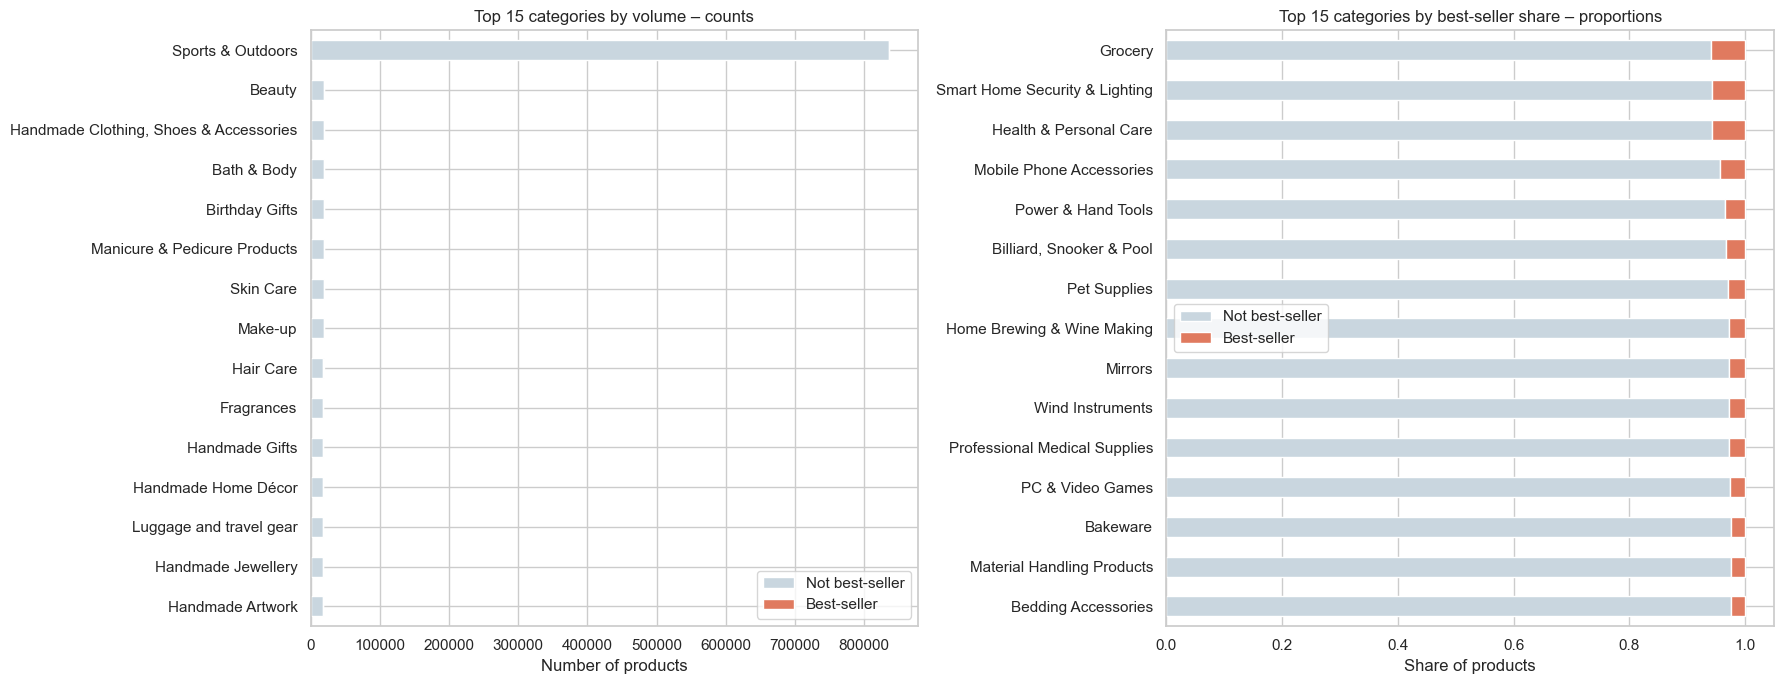

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# (a) Absolute counts, top 15 categories by volume
top15_count = ct.sort_values("Total", ascending=False).head(15).sort_values("Total")
top15_count[["Not best-seller", "Best-seller"]].plot(
    kind="barh", stacked=True, ax=axes[0], color=["#c9d6df", "#e07a5f"])
axes[0].set_title("Top 15 categories by volume – counts")
axes[0].set_xlabel("Number of products")
axes[0].set_ylabel("")

# (b) Proportions, top 15 categories by best-seller share (>= 100 products)
top15_share = ct_sorted_min.head(15).sort_values("Best-seller share")
(top15_share[["Not best-seller", "Best-seller"]]
    .div(top15_share["Total"], axis=0)
    .plot(kind="barh", stacked=True, ax=axes[1], color=["#c9d6df", "#e07a5f"]))
axes[1].set_title("Top 15 categories by best-seller share – proportions")
axes[1].set_xlabel("Share of products")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Reading the charts**

- *Left (counts):* in the most populated categories, best-sellers are a thin slice of the catalogue, which is consistent with the 0.33% overall share.
- *Right (proportions):* once we look at the share rather than the volume, the categories listed in the crosstab (Grocery, Health & Personal Care, Smart Home Security & Lighting, Mobile Phone Accessories, Power & Hand Tools) clearly stand out, but even the best of them stays below 6%. Being a best-seller remains the exception in every category.

# Part 2 – Product prices and ratings across categories and brands

### 2.0 Preliminary step – remove price outliers (IQR method)

In [9]:
# Sanity check: products with a price of 0 usually mean "price not available"
print(f"Products with price == 0: {(df['price'] == 0).mean():.2%}")

Products with price == 0: 0.00%


In [10]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")

df_clean = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)].copy()
print(f"Rows before: {len(df):,} | after: {len(df_clean):,} | removed: {len(df) - len(df_clean):,} ({1 - len(df_clean)/len(df):.1%})")

Q1 = 9.99 | Q3 = 45.99 | IQR = 36.00
Bounds: [-44.01, 99.99]
Rows before: 2,443,651 | after: 2,115,963 | removed: 327,688 (13.4%)


**Outlier removal:** the IQR rule keeps prices up to **£99.99** (Q1 = £9.99, Q3 = £45.99, IQR = £36.00). The lower bound is negative, so nothing is removed at the bottom end (and no product has a price of 0). **327,688 products (13.4%)** are removed, all at the high end. This is a sizeable share, because the price distribution is very right-skewed.

From now on, all analyses of Part 2 and Part 3 use `df_clean`.

### 2.1 Violin plots – price distribution by category

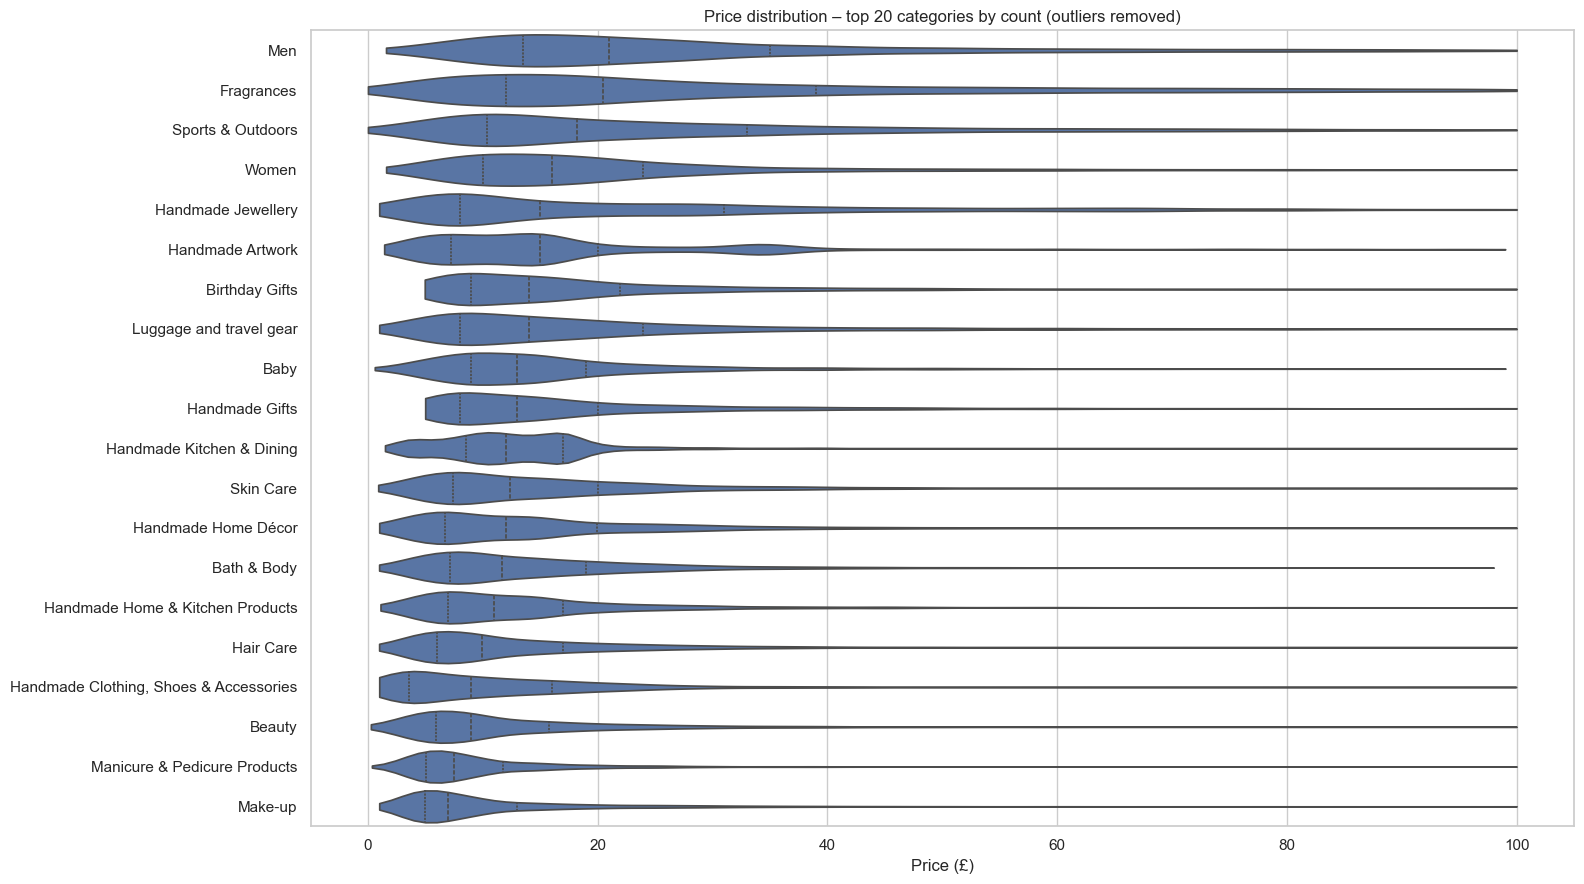

In [11]:
top20_cats = df_clean["category"].value_counts().head(20).index

# Cap the number of points per category for rendering speed only (stats are not computed on this sample)
violin_df = pd.concat([
    df_clean[df_clean["category"] == c].sample(min(5000, (df_clean["category"] == c).sum()), random_state=42)
    for c in top20_cats
])

order = (df_clean[df_clean["category"].isin(top20_cats)]
         .groupby("category")["price"].median().sort_values(ascending=False).index)

plt.figure(figsize=(16, 9))
sns.violinplot(data=violin_df, y="category", x="price", order=order,
               cut=0, inner="quartile", density_norm="width")
plt.title("Price distribution – top 20 categories by count (outliers removed)")
plt.xlabel("Price (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [12]:
# Highest median price – ALL categories (no top-N filter)
median_price = (df_clean.groupby("category")["price"]
                .agg(median="median", mean="mean", n="size")
                .sort_values("median", ascending=False))
print("Top 10 categories by median price (all categories):")
display(median_price.head(10))
print("Same ranking, categories with >= 100 products:")
display(median_price[median_price["n"] >= 100].head(10))

Top 10 categories by median price (all categories):


,median,mean,n
category,,,
Desktop PCs,74.000,66.916,169
Boxing Shoes,69.790,67.418,3873
Tablets,69.000,66.553,4638
Graphics Cards,68.540,65.104,57
Motherboards,67.920,68.772,74
Made in Italy Handmade,64.000,56.398,1561
Digital Frames,63.900,60.745,310
Streaming Clients,62.680,60.242,1692
Golf Shoes,62.390,55.362,4493


Same ranking, categories with >= 100 products:


,median,mean,n
category,,,
Desktop PCs,74.000,66.916,169
Boxing Shoes,69.790,67.418,3873
Tablets,69.000,66.553,4638
Made in Italy Handmade,64.000,56.398,1561
Digital Frames,63.900,60.745,310
Streaming Clients,62.680,60.242,1692
Golf Shoes,62.390,55.362,4493
Ski Helmets,61.330,57.574,161
Hockey Shoes,57.800,60.095,221


**Answer – violin plots and highest median price**

- The violin plots (top 20 categories by count) show distributions concentrated at low prices with a long tail towards the £100 cap; the categories differ mainly in where the bulk of the products sits and in how wide the distribution is.
- **Highest median price (all categories): Desktop PCs, £74.00** (169 products). It stays first when categories with fewer than 100 products are excluded. It is followed by Boxing Shoes (£69.79, 3,873 products) and Tablets (£69.00, 4,638 products). Graphics Cards (57 products) and Motherboards (74 products) also appear in the top 5 but rest on very few products.
- Premium categories are therefore electronics (computing) plus a few specialised sports items.

### 2.2 Bar chart – average price, top 10 categories by count

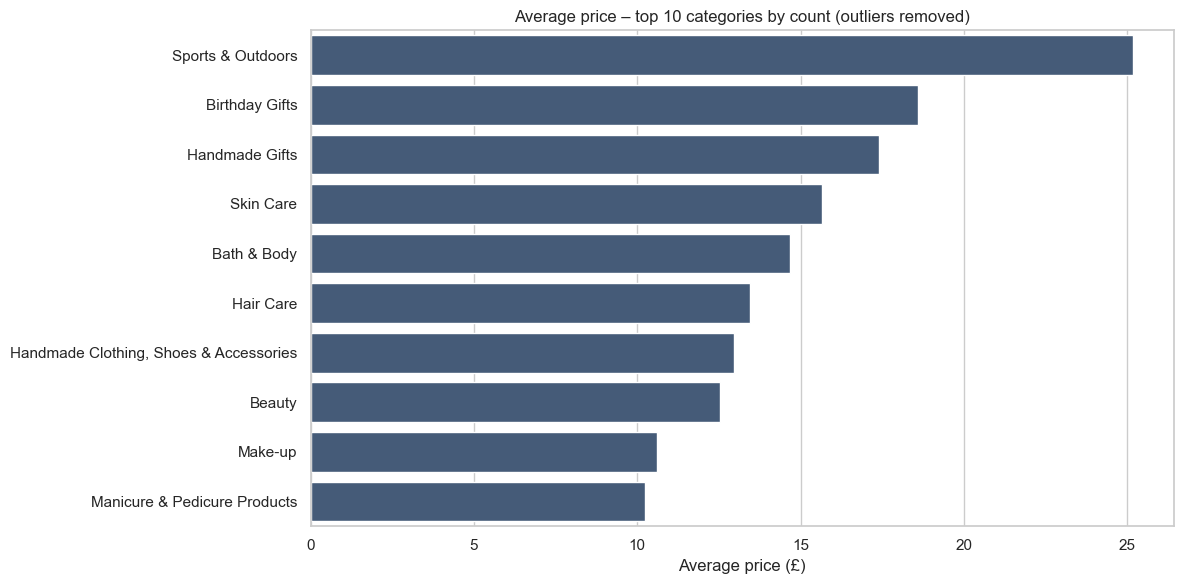

In [13]:
top10_cats = df_clean["category"].value_counts().head(10).index
avg_price_top10 = (df_clean[df_clean["category"].isin(top10_cats)]
                   .groupby("category")["price"].mean().sort_values(ascending=False))

plt.figure(figsize=(12, 6))
sns.barplot(x=avg_price_top10.values, y=avg_price_top10.index, color="#3d5a80")
plt.title("Average price – top 10 categories by count (outliers removed)")
plt.xlabel("Average price (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [14]:
# Highest average price – ALL categories (no top-N filter)
print("Top 10 categories by average price (all categories):")
display(median_price.sort_values("mean", ascending=False).head(10))
print("Same ranking, categories with >= 100 products:")
display(median_price[median_price["n"] >= 100].sort_values("mean", ascending=False).head(10))

Top 10 categories by average price (all categories):


,median,mean,n
category,,,
Motherboards,67.920,68.772,74
Boxing Shoes,69.790,67.418,3873
Desktop PCs,74.000,66.916,169
Tablets,69.000,66.553,4638
Graphics Cards,68.540,65.104,57
Digital Frames,63.900,60.745,310
Streaming Clients,62.680,60.242,1692
Hockey Shoes,57.800,60.095,221
Computer Cases,54.990,58.340,173


Same ranking, categories with >= 100 products:


,median,mean,n
category,,,
Boxing Shoes,69.790,67.418,3873
Desktop PCs,74.000,66.916,169
Tablets,69.000,66.553,4638
Digital Frames,63.900,60.745,310
Streaming Clients,62.680,60.242,1692
Hockey Shoes,57.800,60.095,221
Computer Cases,54.990,58.340,173
Skiing Poles,55.230,57.868,139
Ski Helmets,61.330,57.574,161


**Answer – bar chart and highest average price**

- **Among the 10 most populated categories**, Sports & Outdoors has the highest average price (about £25), followed by Birthday Gifts and Handmade Gifts (about £17–19). Beauty-related categories (Make-up, Manicure & Pedicure Products) are the cheapest, at about £10. The most populated categories are therefore low-ticket, volume-driven segments.
- **Across all categories**, **Motherboards** has the highest average price (**£68.77**) but only 74 products. Restricted to categories with at least 100 products, it is **Boxing Shoes (£67.42, 3,873 products)**, followed by Desktop PCs (£66.92) and Tablets (£66.55).
- Mean and median rankings are close but not identical, which is expected since the mean is more sensitive to expensive items.

### 2.3 Box plots – ratings (`stars`) by category, top 10 categories by count

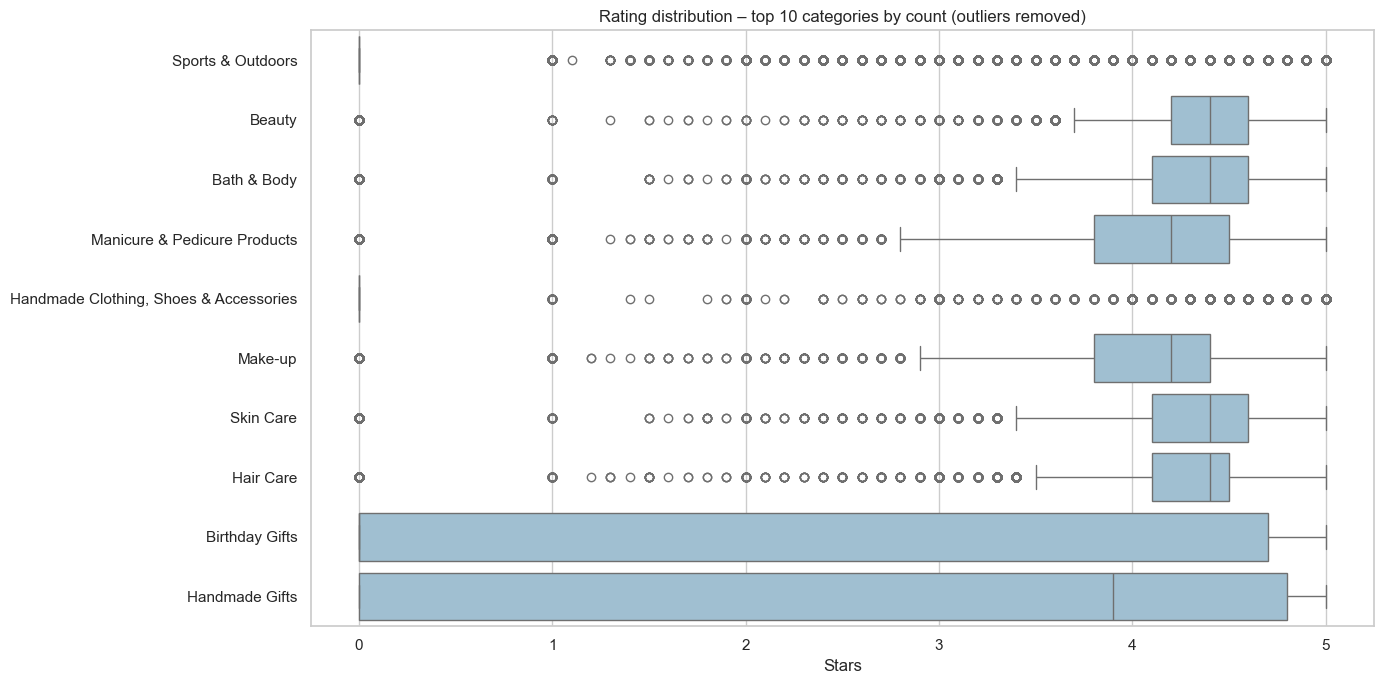

In [15]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_clean[df_clean["category"].isin(top10_cats)],
            x="stars", y="category", order=top10_cats, color="#98c1d9")
plt.title("Rating distribution – top 10 categories by count (outliers removed)")
plt.xlabel("Stars")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [16]:
# Highest median rating – ALL categories (no top-N filter)
median_stars = (df_clean.groupby("category")["stars"]
                .agg(median="median", mean="mean", n="size")
                .sort_values(["median", "mean"], ascending=False))
print("Top 10 categories by median rating (all categories):")
display(median_stars.head(10))
print(f"Number of categories tied at the maximum median: {(median_stars['median'] == median_stars['median'].max()).sum()}")

Top 10 categories by median rating (all categories):


,median,mean,n
category,,,
Computer Memory,4.700,4.300,211
Luxury Food & Drink,4.600,4.544,657
Laptop Accessories,4.600,4.450,250
Office Paper Products,4.600,4.430,9090
Hobbies,4.600,4.190,9065
Kids' Play Figures,4.600,4.173,9377
"Beer, Wine & Spirits",4.600,4.140,9271
Building & Construction Toys,4.600,3.988,8685
Grocery,4.500,4.469,9547


Number of categories tied at the maximum median: 1


In [17]:
# Robustness check: stars == 0 usually means "no rating yet". Same ranking on rated products only
rated = df_clean[df_clean["stars"] > 0]
print(f"Unrated products (stars == 0): {(df_clean['stars'] == 0).mean():.1%}")
median_stars_rated = (rated.groupby("category")["stars"]
                      .agg(median="median", mean="mean", n="size")
                      .sort_values(["median", "mean"], ascending=False))
median_stars_rated[median_stars_rated["n"] >= 100].head(10)

Unrated products (stars == 0): 47.3%


,median,mean,n
category,,,
Handmade Baby Products,5.000,4.663,1235
Handmade Artwork,5.000,4.654,4155
Made in Italy Handmade,5.000,4.607,303
Handmade Kitchen & Dining,4.900,4.611,2739
"Handmade Clothing, Shoes & Accessories",4.900,4.555,4429
Birthday Gifts,4.800,4.581,7875
Handmade Gifts,4.800,4.571,9871
Handmade Home Décor,4.800,4.542,7966
Computer Memory,4.700,4.629,196


**Answer – box plots and highest median rating**

- On the top 10 categories by count, the Beauty-related categories (Beauty, Bath & Body, Skin Care, Hair Care, Make-up, Manicure & Pedicure) have medians between about 4.2 and 4.4 stars. By contrast, Sports & Outdoors, Handmade Clothing, Shoes & Accessories and Birthday Gifts have a median of 0, because more than half of their products are unrated; Handmade Gifts is at about 3.9 with a very wide box.
- **Highest median rating (all categories): Computer Memory, 4.7 stars** (211 products, mean 4.30). It is the only category at this level, and several categories follow at 4.6 (Luxury Food & Drink, Laptop Accessories, Office Paper Products, Hobbies, Kids' Play Figures, Beer, Wine & Spirits, Building & Construction Toys).
- **Important caveat:** **47.3% of products have `stars = 0`**, which means "not rated yet", not "rated zero". This drags the medians of many categories down and makes the 4.7 for Computer Memory partly a reflection of how many of its products are rated. On **rated products only**, the best medians are **5.0** for Handmade Baby Products, Handmade Artwork and Made in Italy Handmade, followed by 4.9 for Handmade Kitchen & Dining and Handmade Clothing, Shoes & Accessories. Handmade categories get excellent ratings from the customers who do rate them.

# Part 3 – Interplay between prices and ratings

### 3.1 Correlation coefficients (`price` vs `stars`)

In [18]:
pearson_r, pearson_p = stats.pearsonr(df_clean["price"], df_clean["stars"])
spearman_r, spearman_p = stats.spearmanr(df_clean["price"], df_clean["stars"])
print(f"Pearson  r   = {pearson_r:.4f} (p = {pearson_p:.2e})")
print(f"Spearman rho = {spearman_r:.4f} (p = {spearman_p:.2e})")

Pearson  r   = -0.0777 (p = 0.00e+00)
Spearman rho = -0.0668 (p = 0.00e+00)


**Answer – is there a significant correlation between price and rating?**

- Pearson r = **−0.078** and Spearman ρ = **−0.067**. Both p-values are ≈ 0, so the correlation is *statistically significant* — but with more than 2 million rows, nearly any non-zero correlation is.
- In practice the relationship is **negligible**: r² ≈ 0.6%, meaning price explains less than 1% of the variation in ratings. The sign is slightly negative: pricier products are, if anything, marginally less well rated.
- **Conclusion:** there is no meaningful link between how much a product costs and how customers rate it.

### 3.2 Visualisations

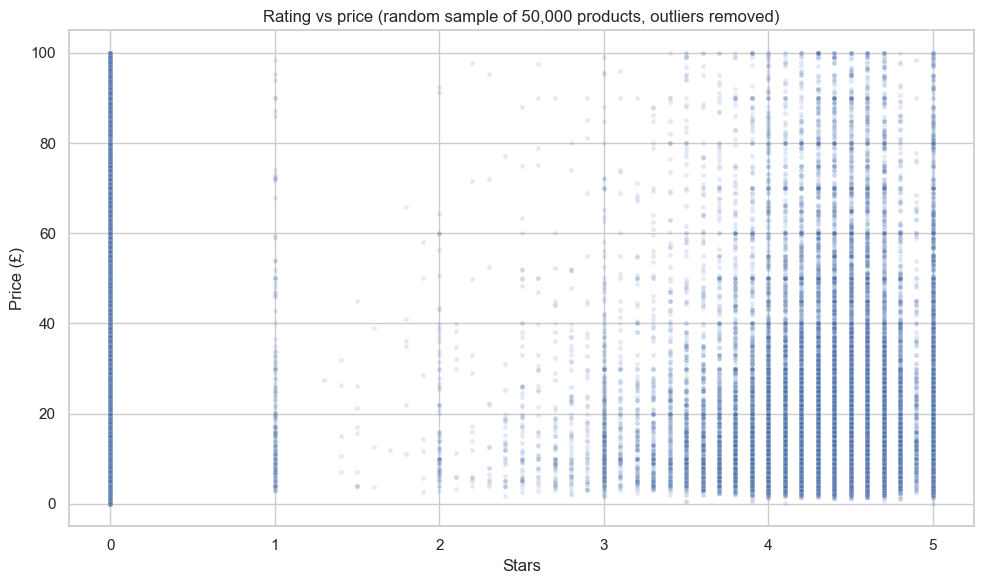

In [19]:
sample = df_clean.sample(50_000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="stars", y="price", alpha=0.15, s=12)
plt.title("Rating vs price (random sample of 50,000 products, outliers removed)")
plt.xlabel("Stars")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

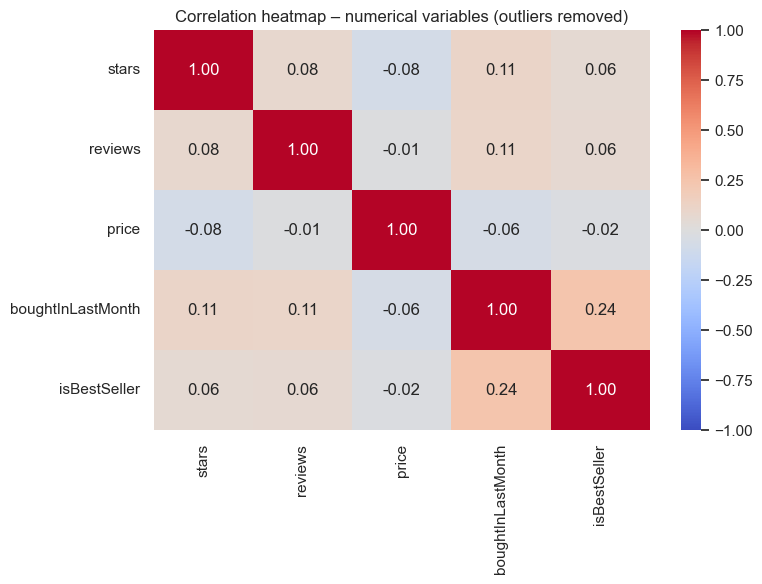

In [20]:
corr_cols = ["stars", "reviews", "price", "boughtInLastMonth", "isBestSeller"]
corr_df = df_clean[corr_cols].astype({"isBestSeller": int})
corr_matrix = corr_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap – numerical variables (outliers removed)")
plt.tight_layout()
plt.show()

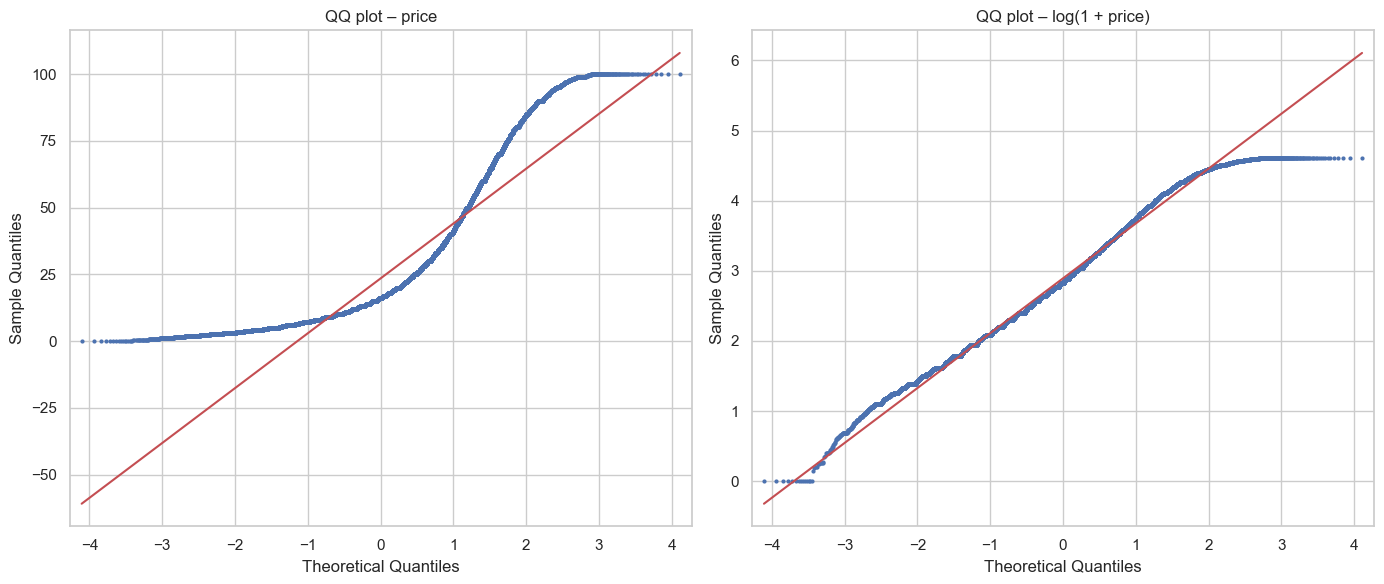

Skewness of price: 1.64


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sm.qqplot(sample["price"], line="s", ax=axes[0], markersize=2)
axes[0].set_title("QQ plot – price")
sm.qqplot(np.log1p(sample["price"]), line="s", ax=axes[1], markersize=2)
axes[1].set_title("QQ plot – log(1 + price)")
plt.tight_layout()
plt.show()

print(f"Skewness of price: {df_clean['price'].skew():.2f}")

**Observations on the visualisations**

- **Scatter plot:** there is no visible trend. The ratings form vertical bands (ratings are given in discrete steps). The `stars = 0` band covers the full price range, which confirms that unrated products are found at every price. Products rated 3.5 and above spread over the whole price range, while low ratings (1 to 3 stars) are rare.
- **Correlation heatmap:** every correlation involving `price` is close to zero (stars −0.08, boughtInLastMonth −0.06, isBestSeller −0.02, reviews −0.01). The strongest relationship in the dataset is between **`boughtInLastMonth` and `isBestSeller` (0.24)**, which makes sense: best-sellers are the products that sell most. It is a weak-to-moderate link, and still far from deterministic.
- **QQ plot:** price is **clearly not normally distributed**, even after removing outliers (skewness = 1.64). The curve is S-shaped: the lower tail is compressed against £0 and the upper tail is cut flat at the £99.99 cap. The log(1 + price) transformation follows the reference line much more closely over the central range, with remaining deviations at both ends (the cap at the top, very cheap products at the bottom). Statistical methods that assume normality should therefore be applied to the log-transformed price.

# Bonus – same analysis without removing outliers

In [22]:
def summarize(data, label):
    med = data.groupby("category")["price"].agg(median="median", mean="mean", n="size")
    med100 = med[med["n"] >= 100]
    return {
        "Dataset": label,
        "Rows": len(data),
        "Mean price": data["price"].mean(),
        "Median price": data["price"].median(),
        "Skewness": data["price"].skew(),
        "Top category by median price (n>=100)": med100["median"].idxmax(),
        "Top category by mean price (n>=100)": med100["mean"].idxmax(),
        "Pearson price/stars": stats.pearsonr(data["price"], data["stars"])[0],
        "Spearman price/stars": stats.spearmanr(data["price"], data["stars"])[0],
    }

comparison = pd.DataFrame([summarize(df_clean, "Without outliers"), summarize(df, "With outliers")]).set_index("Dataset").T
comparison

Dataset,Without outliers,With outliers
Rows,2115963,2443651
Mean price,23.408,89.244
Median price,15.990,19.090
Skewness,1.638,27.493
Top category by median price (n>=100),Desktop PCs,Laptops
Top category by mean price (n>=100),Boxing Shoes,Laptops
Pearson price/stars,-0.078,-0.125
Spearman price/stars,-0.067,-0.133


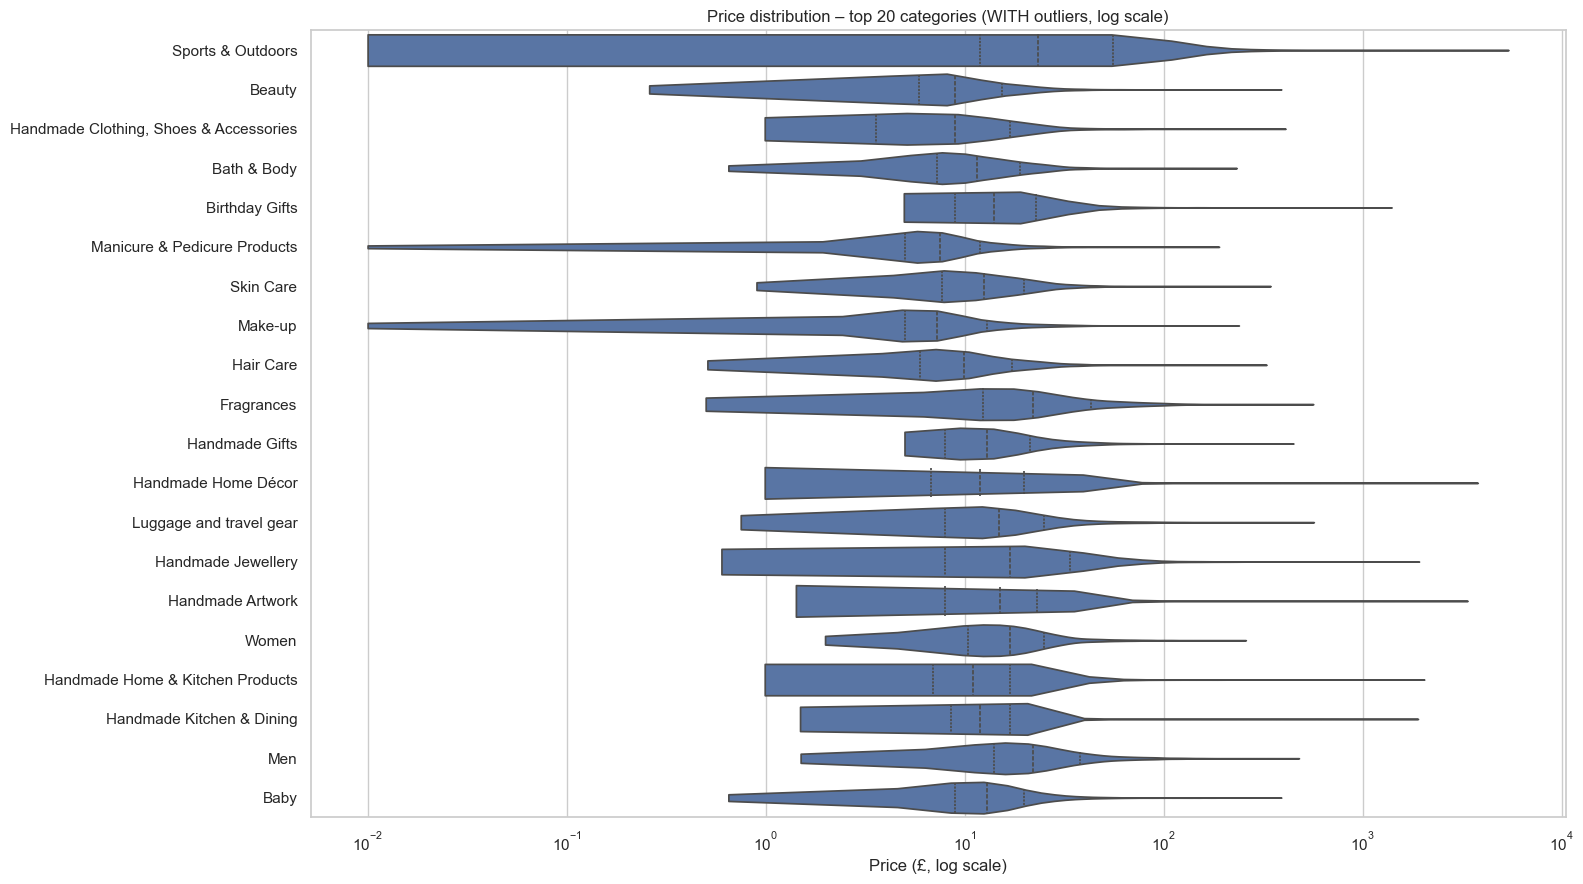

In [23]:
# Violin plot (top 20 categories by count) on the full data – the scale is dominated by extreme prices
top20_full = df["category"].value_counts().head(20).index
violin_full = pd.concat([
    df[df["category"] == c].sample(min(5000, (df["category"] == c).sum()), random_state=42)
    for c in top20_full
])
plt.figure(figsize=(16, 9))
sns.violinplot(data=violin_full, y="category", x="price", cut=0, inner="quartile", density_norm="width")
plt.xscale("log")
plt.title("Price distribution – top 20 categories (WITH outliers, log scale)")
plt.xlabel("Price (£, log scale)")
plt.ylabel("")
plt.tight_layout()
plt.show()

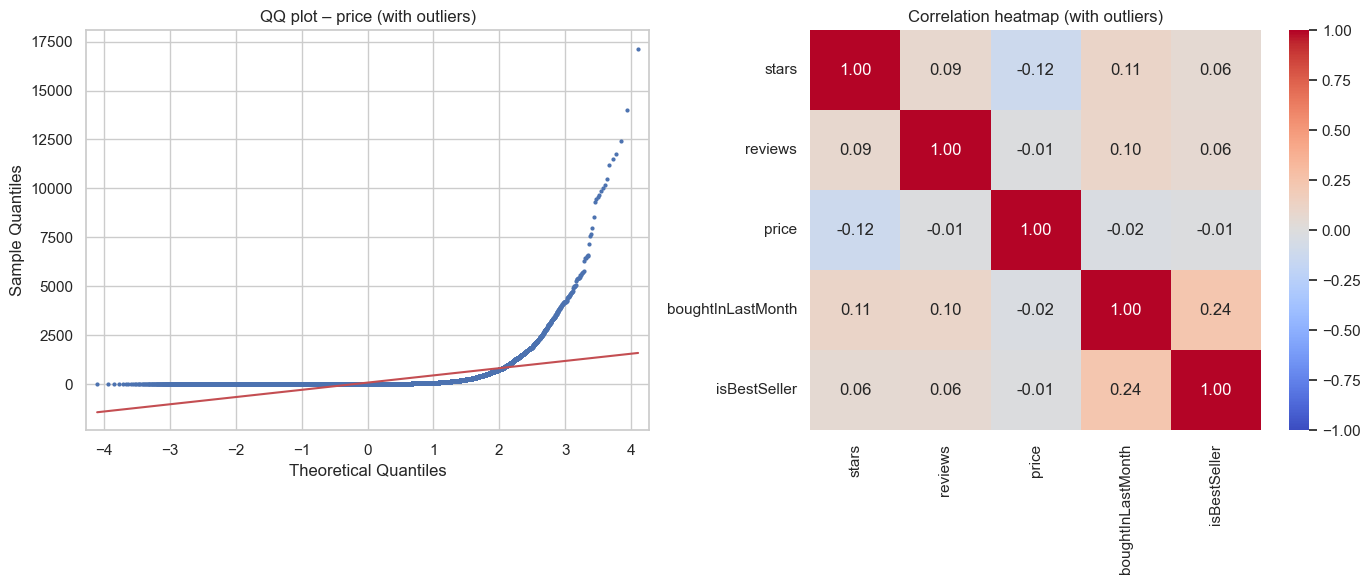

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sample_full = df.sample(50_000, random_state=42)
sm.qqplot(sample_full["price"], line="s", ax=axes[0], markersize=2)
axes[0].set_title("QQ plot – price (with outliers)")
sns.heatmap(df[corr_cols].astype({"isBestSeller": int}).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation heatmap (with outliers)")
plt.tight_layout()
plt.show()

**Bonus – what changes when outliers are kept?**

| | Without outliers | With outliers |
|---|---|---|
| Rows | 2,115,963 | 2,443,651 |
| Mean price | £23.41 | £89.24 |
| Median price | £15.99 | £19.09 |
| Skewness | 1.64 | 27.49 |
| Top category by median price (≥100 products) | Desktop PCs | Laptops |
| Top category by mean price (≥100 products) | Boxing Shoes | Laptops |
| Pearson price/stars | −0.078 | −0.125 |
| Spearman price/stars | −0.067 | −0.133 |

- **The mean is highly unstable:** it is multiplied by about 3.8 (+281%) because of a few extreme prices (the maximum is £100,000), while the **median only moves by 19%**. The median is the reliable indicator when extreme prices are kept. Skewness jumps from 1.64 to 27.49, and the QQ plot with outliers departs from normality even more strongly.
- **Category rankings change:** with outliers, **Laptops** becomes the most expensive category by both median and mean. It was invisible in the cleaned analysis, because its products were mostly removed by the IQR rule. This shows the limit of a global IQR filter: it removes *legitimately* expensive products (laptops, high-end electronics), not just data errors, and therefore biases the comparison between categories towards cheaper ones. A per-category IQR filter would be more appropriate.
- **Correlation:** the price/rating correlation is a little stronger with outliers (−0.125 / −0.133) but remains weak (|r| < 0.15), so the conclusion is the same: price and rating are essentially unrelated.

# Business report – key findings

**Scope:** 2.44M Amazon UK products in 296 categories. For price and rating analyses, 327,688 products above £99.99 (13.4%) were removed with the IQR rule; the bonus shows the results with these products kept.

## 1. Best-seller trends by category
- Best-sellers are rare: **0.33%** of products overall. 260 of 296 categories have at least one.
- The categories with the highest best-seller share are **Grocery (5.8%)**, **Health & Personal Care (5.8%)**, Smart Home Security & Lighting (5.8%, only 104 products), Mobile Phone Accessories (4.2%) and Power & Hand Tools (3.5%).
- The chi-square test (χ² = 36,540, 295 d.f., p ≈ 0) shows that best-seller status **depends on the category**. However, Cramér's V = **0.122** indicates a **weak** association: category is a minor driver.
- *So what?* Grocery and Health & Personal Care combine a high best-seller share with a large catalogue: they offer the best chances of obtaining best-sellers. Category alone should not drive decisions, though; sales volume matters more (`boughtInLastMonth` vs `isBestSeller`: correlation 0.24).

## 2. Prices and ratings by category
- **Highest median price:** Desktop PCs (£74.00). **Highest average price:** Motherboards (£68.77, 74 products); Boxing Shoes (£67.42) if only categories with at least 100 products are considered. Premium segments are mainly computing electronics.
- Among the 10 most populated categories, average prices range from about £10 (Manicure & Pedicure Products) to about £25 (Sports & Outdoors): the largest categories are low-ticket, volume-driven segments.
- **Highest median rating:** Computer Memory (4.7 stars). **47.3% of products are unrated** (`stars = 0`). Among rated products, Handmade categories reach a median of 5.0.
- *So what?* Pricing strategies should be built per segment: premium electronics and mass-market consumer goods do not obey the same price logic.

## 3. Price vs rating
- Pearson r = **−0.078**, Spearman ρ = **−0.067**: statistically significant (very large sample) but **practically negligible** (price explains < 1% of rating variance).
- Price is not normally distributed (skewness 1.64 after cleaning, 27.49 before); log-transformed price is much closer to normal.
- *So what?* A higher price does not signal higher customer satisfaction, and a good rating does not justify a higher price on its own. Neither variable is a good proxy for the other in pricing models.

## 4. Impact of outliers (bonus)
- Keeping outliers multiplies the mean price by ~3.8 (£23.41 → £89.24) but moves the median by only 19% (£15.99 → £19.09): **report medians, not means**.
- A global IQR filter hides entire expensive categories (e.g. Laptops, which become the top category when outliers are kept). Per-category outlier treatment is recommended.

## Recommendations
1. **Assortment & visibility:** prioritise Grocery and Health & Personal Care when looking for best-seller candidates, while monitoring sales volume, which is a stronger signal than category.
2. **Pricing:** define price positioning by segment (premium electronics around £65–75 median vs. £10–25 average in the largest everyday categories) and benchmark each product against its own category, not the whole catalogue.
3. **Ratings:** since 47% of products have no rating, encourage reviews on unrated products; handmade categories show that customers who do rate are very satisfied.
4. **Analytics:** use medians and log-transformed prices in reports and models; avoid using price as a predictor of rating.

## Limitations
- The dataset is a snapshot: `boughtInLastMonth` and best-seller status change over time.
- Categories with few products (e.g. Motherboards, Graphics Cards, Smart Home Security & Lighting) give unstable statistics.
- Unrated products (`stars = 0`) are treated as 0 in the correlation and box plots, which biases the rating analysis.
- The global IQR filter removes legitimately expensive products.
- Correlation does not imply causation; the associations observed here are descriptive.